# Reclamações de passageiros — 2025

Análise exploratória com Python, Pandas e Matplotlib. Pergunta: quais problemas concentram registros e como variam os indicadores de atendimento?

Fonte: ANAC / Consumidor.gov.br; arquivo atualizado em 01/10/2026. Os registros representam reclamações na plataforma, não todos os passageiros nem todos os problemas do setor.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

caminho = Path("dadosconsumidor2025.csv")
if not caminho.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Baixe o CSV oficial e coloque-o ao lado do notebook. Consulte o README.")
    files.upload()


## 1. Importação e qualidade
A primeira linha informa a atualização. A tabela começa na segunda linha, com separador `;` e codificação UTF-8. Não removemos as 10 repetições exatas: sem identificador único, não é possível confirmar que são reclamações duplicadas.

In [2]:
# Importa a tabela, ignorando apenas a linha de atualização.
df = pd.read_csv(
    caminho,
    sep=";",
    skiprows=1,
    encoding="utf-8-sig",
    low_memory=False
)

print(f"Quantidade de registros: {df.shape[0]:,}")
print(f"Quantidade de colunas: {df.shape[1]}")
print("\nColunas disponíveis:")
print("\n".join(df.columns))

display(df.head())


Quantidade de registros: 103,340
Quantidade de colunas: 28

Colunas disponíveis:
Gestor
Região
UF
Cidade
Ano Abertura
Mês Abertura
Data Abertura
Data e Hora Resposta
Data e Hora Análise
Data e Hora Recusa
Data Finalização
Prazo Resposta
Prazo Análise Gestor (em dias)
Tempo Resposta (em dias)
Nome Fantasia
Área
Assunto
Grupo Problema
Problema
Forma Contrato
Procurou Empresa
Respondida
Situação
Avaliação Reclamação
Nota do Consumidor
Edição de Conteúdo
Interação do Gestor
Código Classificador ANAC
                              Gestor Região  UF    Cidade  Ano Abertura  Mês Abertura Data Abertura Data e Hora Resposta Data e Hora Análise Data e Hora Recusa Data Finalização Prazo Resposta  Prazo Análise Gestor (em dias)  Tempo Resposta (em dias)         Nome Fantasia         Área Assunto          Grupo Problema                                                                                      Problema Forma Contrato Procurou Empresa Respondida                 Situação Avaliação Reclamação

In [3]:
print("Registros por ano e mês:")
display(
    df.groupby(["Ano Abertura", "Mês Abertura"], dropna=False)
      .size()
      .reset_index(name="Quantidade")
      .sort_values(["Ano Abertura", "Mês Abertura"])
)

Registros por ano e mês:
    Ano Abertura  Mês Abertura  Quantidade
0           2025             1        8774
1           2025             2        7398
2           2025             3        7963
3           2025             4        7546
4           2025             5        7661
5           2025             6        8110
6           2025             7        8953
7           2025             8        8836
8           2025             9        9394
9           2025            10        9457
10          2025            11        8525
11          2025            12       10723


In [4]:
print("Total de registros:", len(df))
print("Total de colunas:", df.shape[1])

print("\nMeses presentes:")
print(sorted(df["Mês Abertura"].dropna().unique().tolist()))

print("\nLinhas totalmente iguais além da primeira ocorrência:")
print(df.duplicated().sum())

# Resume o tipo e a quantidade de valores ausentes em cada coluna.
qualidade = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "ausentes_%": (df.isna().mean() * 100).round(2)
})

print("\nVerificação por coluna:")
print(qualidade.to_string())

Total de registros: 103340
Total de colunas: 28

Meses presentes:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Linhas totalmente iguais além da primeira ocorrência:
10

Verificação por coluna:
                                   tipo  ausentes  ausentes_%
Gestor                           object         0        0.00
Região                           object         0        0.00
UF                               object         0        0.00
Cidade                           object         0        0.00
Ano Abertura                      int64         0        0.00
Mês Abertura                      int64         0        0.00
Data Abertura                    object         0        0.00
Data e Hora Resposta             object       938        0.91
Data e Hora Análise              object    100893       97.63
Data e Hora Recusa               object    100893       97.63
Data Finalização                 object         3        0.00
Prazo Resposta                   object         0        0.00
Prazo

In [5]:
# Mostra as categorias exatamente como aparecem na base.
for coluna in ["Respondida", "Situação", "Avaliação Reclamação"]:
    print(f"\n--- {coluna} ---")
    print(df[coluna].value_counts(dropna=False).to_string())

print("\n--- Distribuição das notas ---")
print(
    df["Nota do Consumidor"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\n--- Tempo de resposta em dias ---")
print(
    df["Tempo Resposta (em dias)"]
    .describe(percentiles=[0.5, 0.9, 0.95])
    .to_string()
)

print("\nTempos de resposta negativos:")
print((df["Tempo Resposta (em dias)"] < 0).sum())

print("\n--- Anos presentes ---")
print(df["Ano Abertura"].value_counts(dropna=False).to_string())


--- Respondida ---
Respondida
S    102402
N       938

--- Situação ---
Situação
Finalizada avaliada        52058
Finalizada não avaliada    51282

--- Avaliação Reclamação ---
Avaliação Reclamação
Não Avaliada     51260
Resolvida        35394
Não Resolvida    16661
NaN                 25

--- Distribuição das notas ---
Nota do Consumidor
1.0    14702
2.0     1775
3.0     3126
4.0     4739
5.0    27713
NaN    51285

--- Tempo de resposta em dias ---
count    102402.000000
mean          5.627956
std           7.034054
min        -116.000000
50%           7.000000
90%           9.000000
95%          10.000000
max         276.000000

Tempos de resposta negativos:
219

--- Anos presentes ---
Ano Abertura
2025    103340


## 2. Critérios dos indicadores
- Resolução: resolvidas divididas pelas avaliações de desfecho (Resolvida ou Não Resolvida). Não é apresentado como índice oficial.
- Nota média: apenas notas preenchidas; não avaliados não recebem zero.
- Tempo: usamos o campo fornecido pela ANAC, excluindo 219 valores negativos apenas desse cálculo. Os 938 ausentes continuam ausentes. Valores altos positivos são mantidos. A causa dos negativos não foi determinada.
- Mantemos todas as linhas na base. As avaliações são voluntárias e podem não representar os não avaliadores.

In [6]:
# Mantém df intacto e cria uma cópia para a análise.
dados = df.copy()

# Valores negativos ficam ausentes apenas na nova coluna de tempo.
dados["tempo_resposta_valido"] = dados["Tempo Resposta (em dias)"].where(
    dados["Tempo Resposta (em dias)"] >= 0
)

# Identifica os registros que entram no indicador de resolução.
avaliadas = dados["Avaliação Reclamação"].isin(
    ["Resolvida", "Não Resolvida"]
)
resolvidas = dados["Avaliação Reclamação"].eq("Resolvida")

total = len(dados)
total_avaliadas = avaliadas.sum()

print(f"Total de registros: {total}")
print(f"Respondidas: {dados['Respondida'].eq('S').sum()}")
print(f"Percentual respondido: {dados['Respondida'].eq('S').mean():.2%}")

print(f"\nCom avaliação de desfecho: {total_avaliadas}")
print(f"Cobertura da avaliação de desfecho: {total_avaliadas / total:.2%}")
print(f"Resolvidas entre as avaliadas: {resolvidas.sum() / total_avaliadas:.2%}")

print(f"\nNotas preenchidas: {dados['Nota do Consumidor'].count()}")
print(f"Nota média: {dados['Nota do Consumidor'].mean():.2f} de 5")

print(f"\nTempos válidos: {dados['tempo_resposta_valido'].count()}")
print(f"Tempo médio válido: {dados['tempo_resposta_valido'].mean():.2f} dias")
print(f"Mediana do tempo válido: {dados['tempo_resposta_valido'].median():.2f} dias")

Total de registros: 103340
Respondidas: 102402
Percentual respondido: 99.09%

Com avaliação de desfecho: 52055
Cobertura da avaliação de desfecho: 50.37%
Resolvidas entre as avaliadas: 67.99%

Notas preenchidas: 52055
Nota média: 3.56 de 5

Tempos válidos: 102183
Tempo médio válido: 5.80 dias
Mediana do tempo válido: 7.00 dias


## 3. Comparação por empresa
Selecionamos as dez empresas pelo volume de registros, não pela taxa de resolução. Coberturas de avaliação e tempos válidos variam. Não há ajuste por passageiros, rotas ou tipo de problema; não é um ranking geral de qualidade.

In [7]:
# Cria indicadores por registro para permitir a contagem por empresa.
dados["avaliada_desfecho"] = dados["Avaliação Reclamação"].isin(
    ["Resolvida", "Não Resolvida"]
)
dados["resolvida"] = dados["Avaliação Reclamação"].eq("Resolvida")

empresas = (
    dados.groupby("Nome Fantasia", dropna=False)
    .agg(
        reclamacoes=("Nome Fantasia", "size"),
        avaliadas=("avaliada_desfecho", "sum"),
        resolvidas=("resolvida", "sum"),
        notas_recebidas=("Nota do Consumidor", "count"),
        nota_media=("Nota do Consumidor", "mean"),
        tempos_validos=("tempo_resposta_valido", "count"),
        tempo_medio_dias=("tempo_resposta_valido", "mean")
    )
)

# Evita calcular resolução quando não há avaliações.
empresas["resolucao_%"] = (
    empresas["resolvidas"]
    .div(empresas["avaliadas"].where(empresas["avaliadas"] > 0))
    .mul(100)
)

empresas["cobertura_avaliacao_%"] = (
    empresas["avaliadas"] / empresas["reclamacoes"] * 100
)

empresas = empresas.sort_values("reclamacoes", ascending=False)

print("10 empresas com mais registros na base:")
print(empresas.head(10).round(2).to_string())

10 empresas com mais registros na base:
                                      reclamacoes  avaliadas  resolvidas  notas_recebidas  nota_media  tempos_validos  tempo_medio_dias  resolucao_%  cobertura_avaliacao_%
Nome Fantasia                                                                                                                                                              
Azul Linhas Aéreas                          37076      19521       14915            19521        3.88           36999              6.97        76.40                  52.65
Latam Airlines (Tam)                        29646      15820       11837            15820        3.80           29520              3.61        74.82                  53.36
Gol Linhas Aéreas                           18804       9234        6736             9234        3.74           18735              6.81        72.95                  49.11
Iberia Lineas Aereas                         2395        986         199              986        1.7

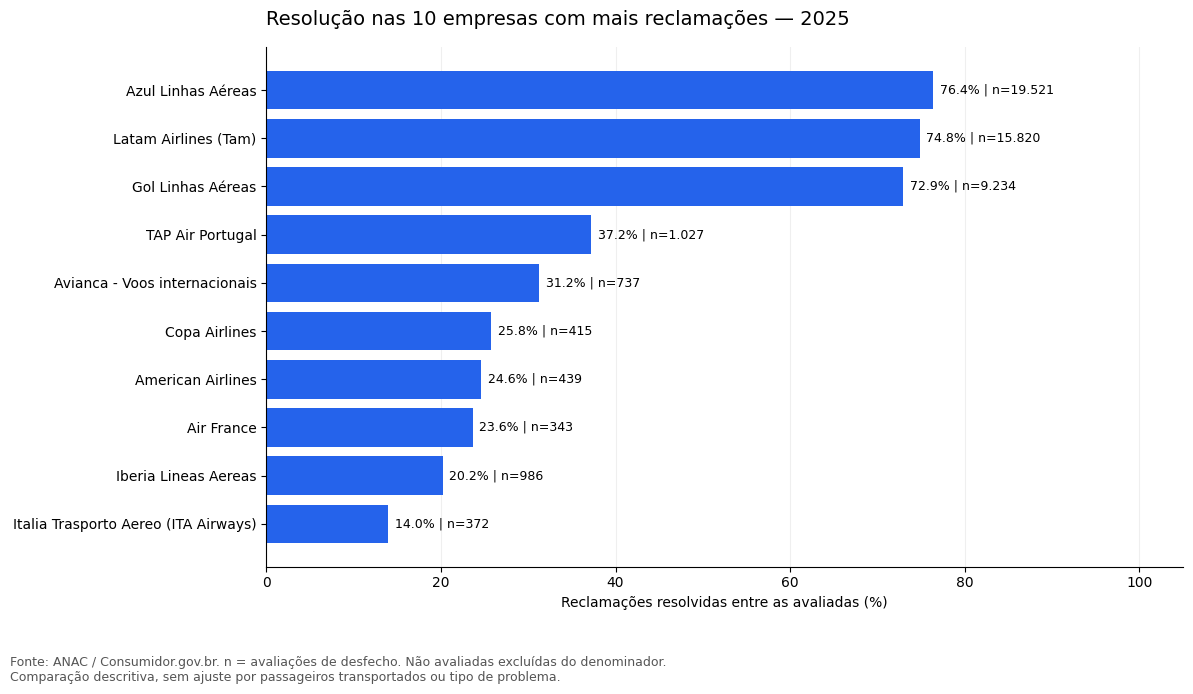

In [8]:
from pathlib import Path

# Seleciona por volume e ordena pela resolução para facilitar a leitura.
top10 = empresas.head(10).sort_values("resolucao_%")

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    top10.index,
    top10["resolucao_%"],
    color="#2563EB"
)

# Mostra o percentual e a quantidade de avaliações usadas.
rotulos = [
    f"{taxa:.1f}% | n={int(n):,}".replace(",", ".")
    for taxa, n in zip(top10["resolucao_%"], top10["avaliadas"])
]

ax.bar_label(barras, labels=rotulos, padding=5, fontsize=9)

ax.set_xlim(0, 105)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Reclamações resolvidas entre as avaliadas (%)")
ax.set_ylabel("")
ax.set_title(
    "Resolução nas 10 empresas com mais reclamações — 2025",
    loc="left",
    fontsize=14,
    pad=16
)

ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

fig.text(
    0.01, 0.02,
    "Fonte: ANAC / Consumidor.gov.br. "
    "n = avaliações de desfecho. Não avaliadas excluídas do denominador.\n"
    "Comparação descritiva, sem ajuste por passageiros transportados "
    "ou tipo de problema.",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

Path("graficos").mkdir(exist_ok=True)
fig.savefig(
    "graficos/resolucao_por_empresa.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 4. Problemas mais frequentes
As categorias originais são preservadas. A participação usa os 103.340 registros como denominador.

In [9]:
problemas = (
    dados["Problema"]
    .value_counts(dropna=False)
    .rename_axis("problema")
    .reset_index(name="reclamacoes")
)

problemas["participacao_%"] = (
    problemas["reclamacoes"] / len(dados) * 100
)

print(problemas.head(10).round(2).to_string(index=False))

participacao_top3 = (
    problemas.head(3)["reclamacoes"].sum() / len(dados) * 100
)

print(
    f"\nOs três problemas mais frequentes representam "
    f"{participacao_top3:.2f}% dos registros."
)

                                                                            problema  reclamacoes  participacao_%
                                                                 Cancelamento de voo        11601           11.23
Dificuldade / atraso na devolução de valores pagos / reembolso / retenção de valores        10676           10.33
   Extravio/ avaria de bagagem, carga, correspondência (ressarcimento, indenizações)        10551           10.21
                     Cobrança indevida / abusiva para alterar ou cancelar o contrato         9337            9.04
                                                                       Atraso de voo         8170            7.91
  Oferta não cumprida / serviço não fornecido/ venda enganosa / publicidade enganosa         6784            6.56
              SAC - Demanda não resolvida / não respondida / respondida após o prazo         6070            5.87
          Dificuldade / demora para alterar o contrato de serviço (alteração de voo)    

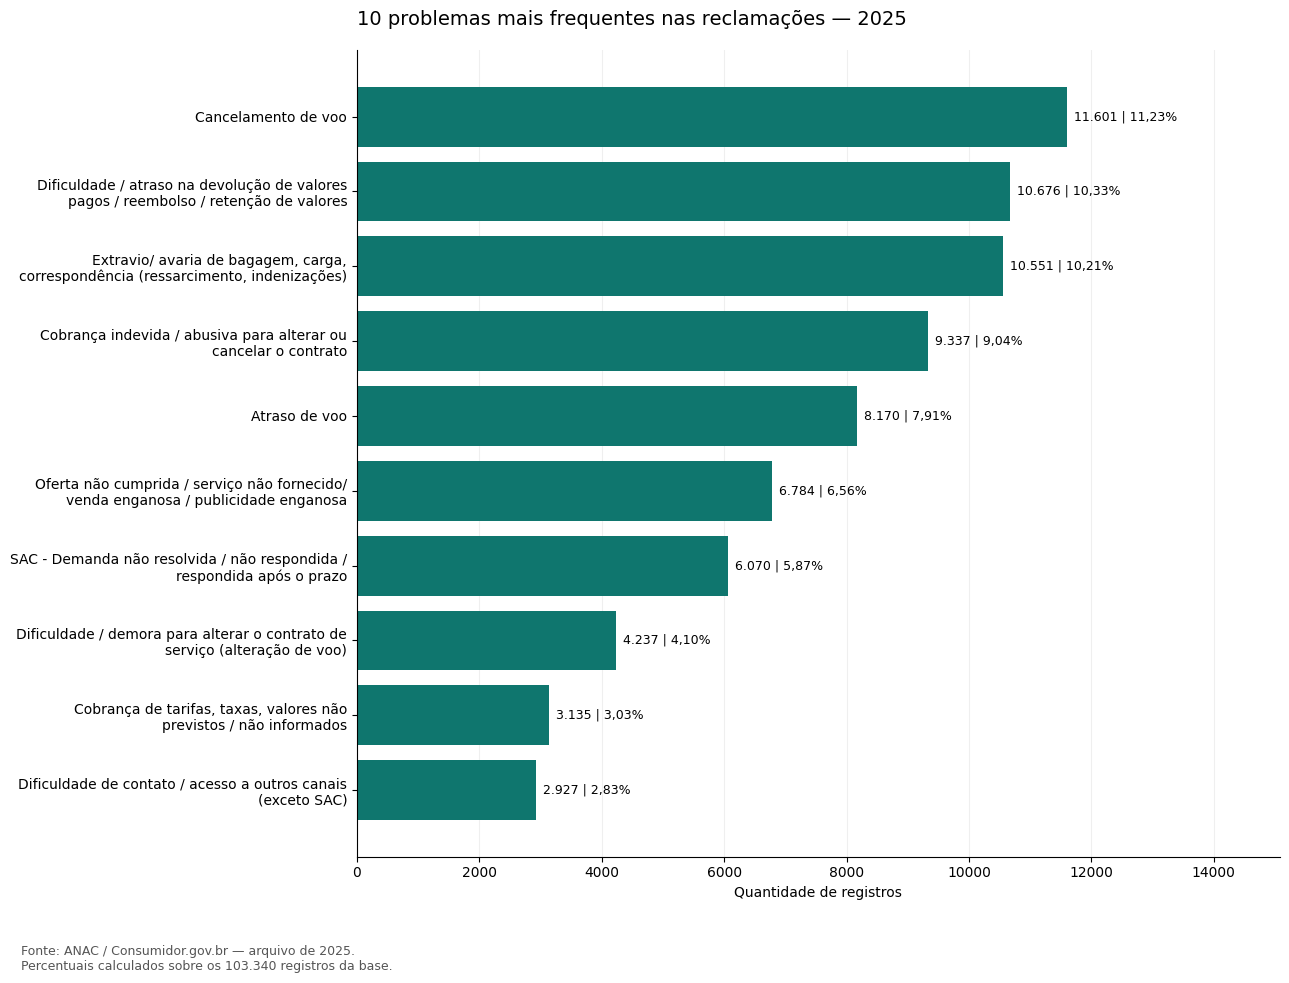

In [10]:
import textwrap
from pathlib import Path

top_problemas = problemas.head(10).iloc[::-1]

# Quebra os textos longos em linhas, sem alterar as categorias.
nomes = [
    textwrap.fill(str(nome), width=48)
    for nome in top_problemas["problema"]
]

fig, ax = plt.subplots(figsize=(13, 10))

barras = ax.barh(
    nomes,
    top_problemas["reclamacoes"],
    color="#0F766E"
)

rotulos = [
    f"{int(qtd):,}".replace(",", ".")
    + " | "
    + f"{pct:.2f}%".replace(".", ",")
    for qtd, pct in zip(
        top_problemas["reclamacoes"],
        top_problemas["participacao_%"]
    )
]

ax.bar_label(barras, labels=rotulos, padding=5, fontsize=9)
ax.set_xlim(0, top_problemas["reclamacoes"].max() * 1.30)
ax.set_xlabel("Quantidade de registros")
ax.set_title(
    "10 problemas mais frequentes nas reclamações — 2025",
    loc="left",
    fontsize=14,
    pad=18
)

ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

fig.text(
    0.02, 0.025,
    "Fonte: ANAC / Consumidor.gov.br — arquivo de 2025.\n"
    "Percentuais calculados sobre os 103.340 registros da base.",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

Path("graficos").mkdir(exist_ok=True)
fig.savefig(
    "graficos/problemas_mais_frequentes.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 5. Evolução mensal
Contagem pelo mês de abertura, não pelo mês do voo. Um ano não permite demonstrar sazonalidade. Janeiro não tem variação calculada por falta de dezembro de 2024.

In [11]:
mensal = (
    dados.groupby("Mês Abertura")
    .size()
    .rename("reclamacoes")
    .sort_index()
    .to_frame()
)

mensal["variacao_mensal_%"] = (
    mensal["reclamacoes"].pct_change() * 100
)

print(mensal.round(2).to_string())

              reclamacoes  variacao_mensal_%
Mês Abertura                                
1                    8774                NaN
2                    7398             -15.68
3                    7963               7.64
4                    7546              -5.24
5                    7661               1.52
6                    8110               5.86
7                    8953              10.39
8                    8836              -1.31
9                    9394               6.32
10                   9457               0.67
11                   8525              -9.86
12                  10723              25.78


Gráfico e tabelas salvos no Colab.


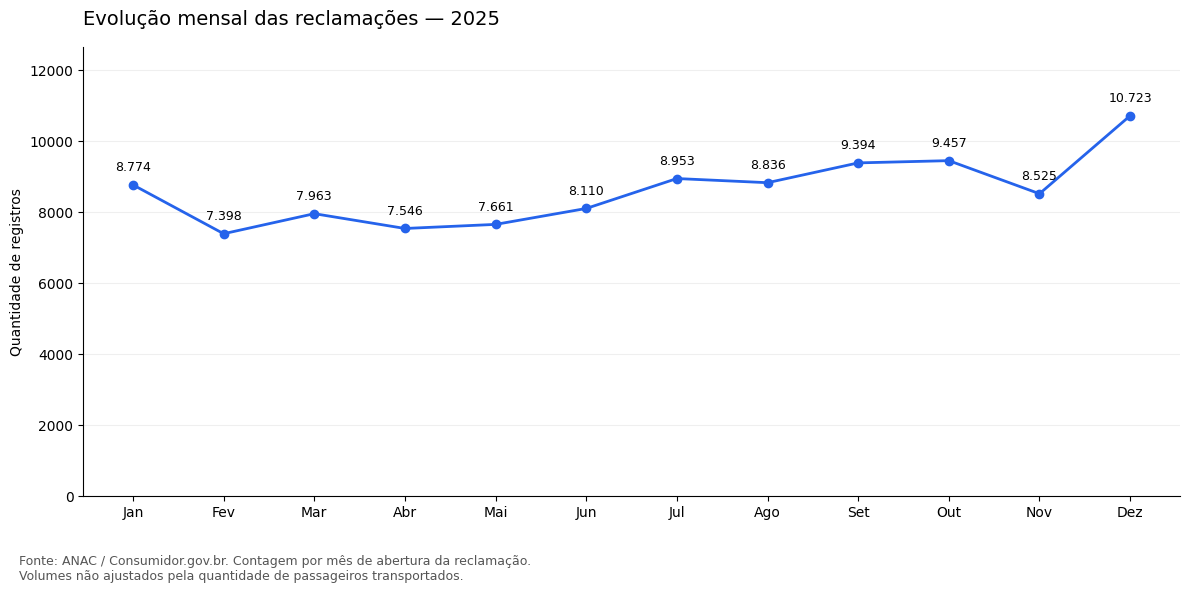

In [12]:
from pathlib import Path

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    mensal.index,
    mensal["reclamacoes"],
    color="#2563EB",
    marker="o",
    linewidth=2
)

for mes, quantidade in mensal["reclamacoes"].items():
    ax.annotate(
        f"{quantidade:,}".replace(",", "."),
        (mes, quantidade),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xticks(range(1, 13), meses)
ax.set_ylim(0, mensal["reclamacoes"].max() * 1.18)
ax.set_ylabel("Quantidade de registros")
ax.set_title(
    "Evolução mensal das reclamações — 2025",
    loc="left",
    fontsize=14,
    pad=16
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.02, 0.025,
    "Fonte: ANAC / Consumidor.gov.br. "
    "Contagem por mês de abertura da reclamação.\n"
    "Volumes não ajustados pela quantidade de passageiros transportados.",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

Path("graficos").mkdir(exist_ok=True)
fig.savefig(
    "graficos/evolucao_mensal.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Exporta os resultados completos, sem arredondar os dados.
Path("resultados").mkdir(exist_ok=True)

empresas.to_csv(
    "resultados/indicadores_por_empresa.csv",
    encoding="utf-8-sig"
)
problemas.to_csv(
    "resultados/problemas.csv",
    index=False,
    encoding="utf-8-sig"
)
mensal.to_csv(
    "resultados/evolucao_mensal.csv",
    encoding="utf-8-sig"
)

print("Gráfico e tabelas salvos no Colab.")

## 6. Conclusões e próximos passos
- 103.340 registros de 2025; 99,09% respondidos. Resposta não significa resolução.
- 67,99% de resolução entre 52.055 avaliações de desfecho, cobertura de 50,37% da base. Nota média de 3,56 entre notas preenchidas.
- Tempo médio de 5,80 dias e mediana de 7 dias, em 102.183 tempos não negativos e preenchidos.
- Cancelamento de voo, reembolso e extravio/avaria de bagagem, carga ou correspondência somam 31,77% dos registros. São prioridades para investigação, sem estimar redução futura.
- Dezembro registra 10.723 reclamações, aumento de 25,78% sobre novembro. Os dados não comprovam a causa.

Próximas análises: comparar resolução por tipo de problema, investigar tempos negativos na origem e incorporar volume de passageiros e outros anos.

Há 52.058 registros com situação Finalizada avaliada e 52.055 com desfecho explícito. Essa diferença de totais não identifica sozinha quais linhas divergem. Consulte o cruzamento abaixo.

In [13]:
print(pd.crosstab(df["Situação"], df["Avaliação Reclamação"].fillna("Ausente")).to_string())

Avaliação Reclamação     Ausente  Não Avaliada  Não Resolvida  Resolvida
Situação                                                                
Finalizada avaliada            3             0          16661      35394
Finalizada não avaliada       22         51260              0          0
